In [1]:
import os, sys
cur_directory = os.getcwd()
project_folder = os.path.abspath(os.path.join(cur_directory, os.pardir))
save_directory = os.path.join(cur_directory, 'saved')
sys.path.append(os.path.join(project_folder, 'analysis-suite'))

In [2]:
import numpy as np
import matplotlib as mpl
from matplotlib import pyplot as plt
import analyses as als
import datasets as ds
import models as mds
import tools
from random import sample
from tqdm import tqdm
from argparse import Namespace
from time import gmtime, strftime
import pickle

from plot_preferences import *


In [3]:
stimuli = ['bushes', 'water', 'leaves', 'fish', 'opticflow']

colors = np.array([[0.8, 0.3, 0.7],
       [0.8, 0.5, 0.3],
       [0.5, 0.8, 0.3],
       [0.3, 0.8, 0.7],
       [0.3, 0.3, 0.8]])

load_path = project_folder + '/analyses/cross-stim performance/saved/pairwise_10_repeats_16_iter.dat'
with open(load_path, 'rb') as f:
    data_dict = pickle.load(f)
data = Namespace(**data_dict)

In [37]:
I_normed = data.mi_average_test / np.diag(data.mi_average_test)[None,:]
I = data.mi_average_test / np.log(2)
I_err = data.mi_stdevs_test / np.log(2)
I_ctl = np.diag(I)
off_diag_mask = (np.ones_like(I) - np.eye(5)).astype(bool)
I_nov_avg = np.sum(off_diag_mask * I, axis=0) / 4
I_nov = np.zeros((5,4))
I_nov_err = np.zeros((5,4))
for n in range(5):
    sel = off_diag_mask[n]
    I_nov[n] = I[sel, n]
    I_nov_err[n] = I_err[sel, n]

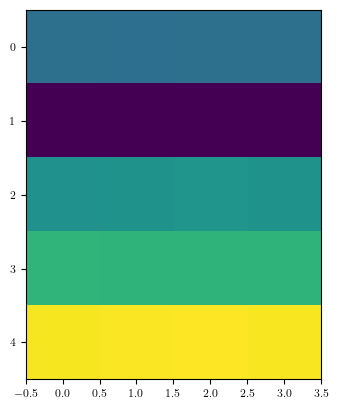

In [38]:
plt.imshow(I_nov)

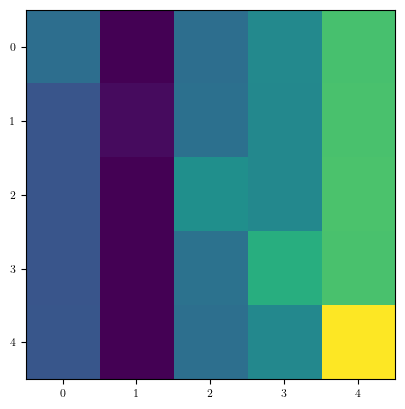

In [39]:
plt.imshow(I)

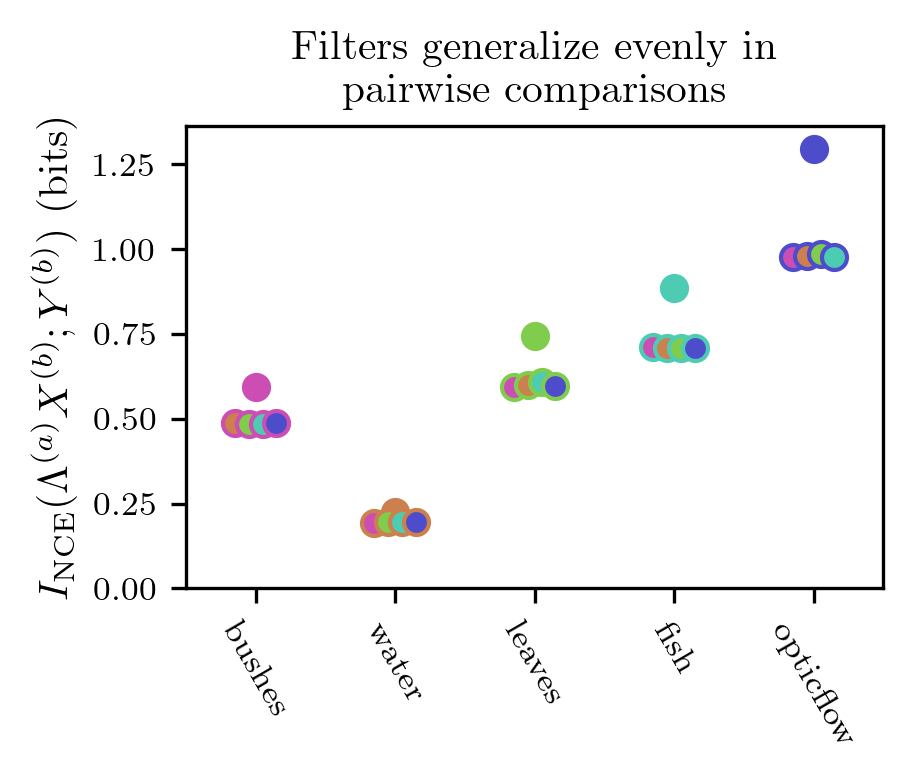

In [79]:
alp = 0.1
margin = 0.5
# plot_scale = 0.7
plot_scale = 0.5
w = 0.3

fig, ax = plt.subplots(figsize=[6*plot_scale,4*plot_scale], dpi=300)

for j, stim in enumerate(stimuli):
    x = j
    y = I[j,j]
    y_err = I_err[j,j]
    ax.errorbar(x, y, y_err, marker='o', color=colors[j])


    x = j + np.linspace(-w/2, w/2, 4)
    c = 0
    for n in range(5):
        if n == j:
            continue
        else:
            y = I[n, j]
            y_err = I_err[n, j]
            ax.errorbar(x[c], y, y_err, marker='o', color=colors[n], linestyle='', markeredgecolor=colors[j])
            c += 1


# ax.errorbar([],[], marker='o', color=colors[0], label='trained, tested on bushes')
# ax.errorbar([],[], marker='o', color=colors[0], markeredgecolor=colors[1], label='trained on bushes, tested on water')
# ax.legend()

ax.set_ylim(0)
ax.set_xlim( -margin, 4 + margin)
ax.set_xticks(np.arange(5))
ax.set_xticklabels(stimuli)
ax.tick_params(axis='x', labelrotation=-60)
# ax.set_yticks([0,1])
ax.set_ylabel("$I_{\mathrm{NCE}}(\Lambda^{(a)}X^{(b)};Y^{(b)})$ (bits)")
ax.set_title("Filters generalize evenly in\n pairwise comparisons")    
# fig.savefig('./plots/compressibility across stim.svg', bbox_inches="tight")
fig.savefig('./plots/pairwise_left.png', dpi=3000)

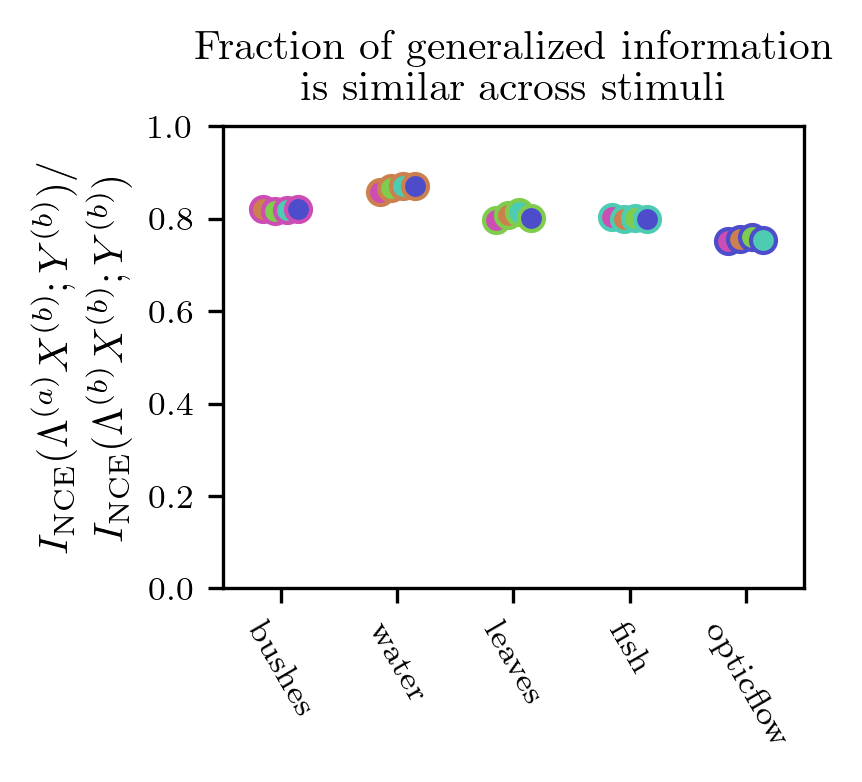

In [80]:
alp = 0.1
margin = 0.5
# plot_scale = 0.7
plot_scale = 0.5
w = 0.3

fig, ax = plt.subplots(figsize=[5*plot_scale,4*plot_scale], dpi=300)

for j, stim in enumerate(stimuli):
    # x = j
    # y = I[j,j]
    # y_err = I_err[j,j]
    # ax.errorbar(x, y, y_err, marker='o', color=colors[j])

    x = j + np.linspace(-w/2, w/2, 4)
    c = 0
    for n in range(5):
        if n == j:
            continue
        else:
            y = I[n, j] / I[j, j]
            y_err = I_err[n, j] / I[j, j]
            ax.errorbar(x[c], y, y_err, marker='o', color=colors[n], linestyle='', markeredgecolor=colors[j])
            c += 1


# ax.errorbar([],[], marker='o', color=colors[0], label='trained, tested on bushes')
# ax.errorbar([],[], marker='o', color=colors[0], markeredgecolor=colors[1], label='trained on bushes, tested on water')
# ax.legend()

ax.set_ylim(0, 1)
ax.set_xlim( -margin, 4 + margin)
ax.set_xticks(np.arange(5))
ax.set_xticklabels(stimuli)
ax.tick_params(axis='x', labelrotation=-60)
# ax.set_yticks([0,1])
ax.set_ylabel("$I_{\mathrm{NCE}}(\Lambda^{(a)}X^{(b)};Y^{(b)}) /$\n $I_{\mathrm{NCE}}(\Lambda^{(b)}X^{(b)};Y^{(b)})$")
ax.set_title("Fraction of generalized information \n is similar across stimuli")    
fig.savefig('./plots/pairwise_right', dpi=3000)

In [72]:
I_nov_avg

array([0.48528401, 0.19555662, 0.59929784, 0.70972868, 0.97921816])

In [77]:
np.sqrt(np.var(I_nov, axis=1))

array([0.00136078, 0.00122712, 0.00515443, 0.00134105, 0.00386072])

In [78]:
I_nov

array([[0.486005  , 0.48335756, 0.48478011, 0.48699338],
       [0.19348495, 0.19581325, 0.19636836, 0.19655993],
       [0.59340345, 0.60066348, 0.6070124 , 0.59611205],
       [0.71202158, 0.70885272, 0.7093075 , 0.70873291],
       [0.97504654, 0.97927059, 0.98538456, 0.97717097]])